In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.animation import FuncAnimation
import geopandas as gpd

In [11]:
df = pd.read_csv(r"data\final.csv")
df = df.drop(df[df["population"].isna()].index)
df = df.drop(df[df['name'].str.endswith('apskritis')].index)
df.head(5)

,name,year,month,infection,forest cover,population,area,oro_temp,juntamoji_temp,debesuotumas,slegis_juros_lyg,santyk_oro_dregme,kritutliu_kiekis
1,Alytaus m. sav.,2004,3,1,30.4,70053.0,39.0,1.406452,NaN,NaN,NaN,NaN,40.3
2,Druskininkų sav.,2004,3,0,69.2,24665.0,453.0,1.687097,NaN,NaN,NaN,NaN,41.4
3,Alytaus r. sav.,2004,3,0,24.6,31741.0,1403.0,1.406452,NaN,NaN,NaN,NaN,40.3
4,Lazdijų r. sav.,2004,3,0,34.8,26221.0,1306.0,1.687097,NaN,NaN,NaN,NaN,41.4
5,Varėnos r. sav.,2004,3,0,69.0,30071.0,2216.0,1.406452,NaN,NaN,NaN,NaN,40.3


cases below 30 make up 64.0 % of cases and 98.0 % of datapoints


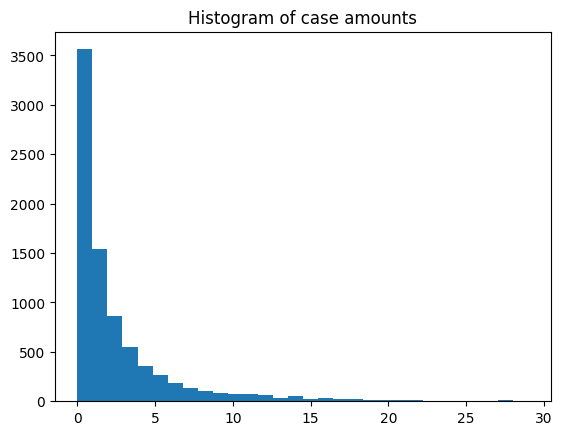

In [12]:
thresh = 30  
belowSeries = df[df['infection'] < thresh]['infection']
print(f"cases below {thresh} make up {round(100*sum(belowSeries)/sum(df['infection']),0)} % of cases and {round(100*len(belowSeries)/len(df['infection']),0)} % of datapoints")
plt.hist(belowSeries,bins=thresh)
plt.title("Histogram of case amounts")
plt.show()

In [13]:
import xgboost as xgb
model = xgb.XGBRegressor()
model.load_model("current_model.json")

Kauno m. sav. MAE: 13.351851851851851
Vilniaus m. sav. MAE: 24.187919463087248


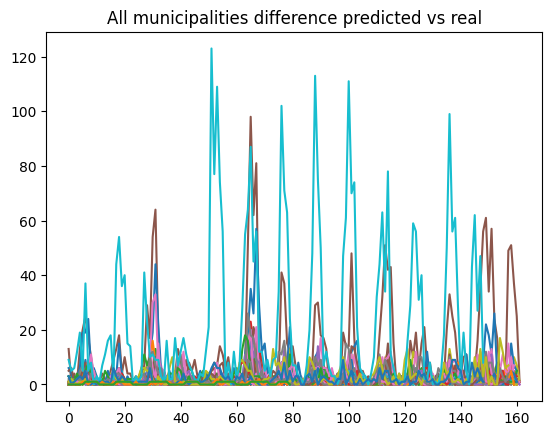

In [14]:
l = []
for location in df['name'].unique():
    X_test = df[(df["name"] == location)].drop(columns=["infection", "name"])
    y_test = df[(df["name"] == location)]["infection"]
    y_pred = model.predict(X_test)
    y_pred = list(round(y,0) for y in np.expm1(y_pred))
    if len(y_test) == 0:
        print(location)
        continue
    tempx = list(range(len(y_test)))
    mae = sum(abs(y_pred-y_test))/len(y_test)
    plt.title(f'{location} MAE: {mae}')
    if mae> 9: print(f'{location} MAE: {mae}')
    l.append(mae)
    #plt.plot(tempx,y_test, label="Real Cases")
    #plt.plot(tempx,y_pred, label="Predictions")
    plt.plot(tempx,abs(y_test-y_pred), label="Difference")
    #plt.legend()
    #plt.show()
plt.title("All municipalities difference predicted vs real")
plt.show()

In [15]:
X_test = df[(df["year"] >= 2017)].drop(columns=["infection", "name"])
y_test = df[(df["year"] >= 2017)]["infection"]
y_pred = model.predict(X_test)
y_pred = list(round(y,0) for y in np.expm1(y_pred))


sum predictions 2194.0
sum true vals 4405
percentage of cases 0.49807037457434733
Mean absolute error 2.6767578125


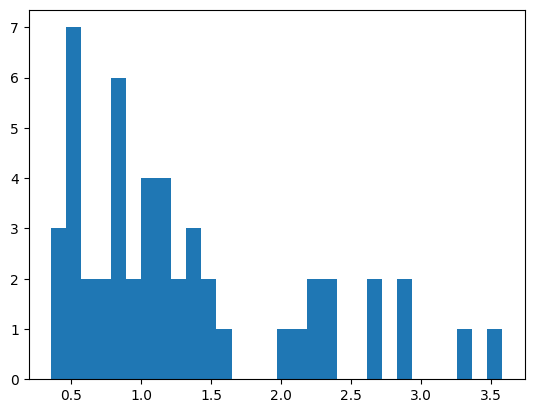

In [16]:
print("sum predictions", sum(y_pred)) 
print("sum true vals", sum(y_test))
print("percentage of cases", sum(y_pred)/sum(y_test))
print("Mean absolute error", sum(abs(y_pred-y_test))/len(y_test))
plt.hist(sorted(l)[:-3],bins=30)
plt.show()

In [17]:
for location in df['name'].unique():
    X_test = df[(df["name"] == location)].drop(columns=["infection", "name"]).reset_index(drop=True)
    y_test = np.array(df[(df["name"] == location)]["infection"])
    y_pred = model.predict(X_test)
    y_pred = np.round(np.expm1(y_pred), 0).astype(int)
    for year in range(2015,2016):
        if year == 2016: continue
        mask = X_test[X_test['year'] == year].index
        percentage_error = sum(abs(y_test[mask]-y_pred[mask]))/sum(y_test[mask])
        mae = sum(abs(y_test[mask]-y_pred[mask]))/len(y_test[mask])
        #print(f'percentage error for {year} in {location[:10]}: {round(100*percentage_error,1)} %, MAE : {round(mae,1)}')

C:\Users\user\AppData\Local\Temp\ipykernel_11800\2497715381.py:9: RuntimeWarning: divide by zero encountered in scalar divide
  percentage_error = sum(abs(y_test[mask]-y_pred[mask]))/sum(y_test[mask])


In [23]:
X_train = df[df["year"] < 2017].drop(columns=["infection", "name"])
y_train = df[df["year"] < 2017]["infection"]

X_test = df[df["year"] >= 2017].drop(columns=["infection", "name"])
y_test = df[df["year"] >= 2017]["infection"]

y_train_log = np.log1p(y_train)

model.fit(X_train, y_train_log)
y_pred_log = model.predict(X_test)
y_pred = np.expm1(y_pred_log)

from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error

mae_test = mean_absolute_error(y_test, y_pred)
rmse_test = mean_squared_error(y_test, y_pred)
r2_test = r2_score(y_test, y_pred)

print("Temporal Test MAE:", mae_test)
print("Temporal Test RMSE:", (rmse_test))
print("Temporal Test R²:", r2_test)

Temporal Test MAE: 2.5015206336975098
Temporal Test RMSE: 43.17405700683594
Temporal Test R²: 0.6807228326797485


In [21]:
y_train

1        1
2        0
3        0
4        0
5        0
        ..
8851     0
8852     0
8853     2
8854     4
8855    29
Name: infection, Length: 7246, dtype: int64

In [ ]:
gdf = gpd.read_file(r"data\raw\adr_gra_savivaldybes.json")

In [ ]:

years = list(range(1,13))
munis = gdf["SAV_PAV"].tolist()
arr1 = df['name'].unique()
for name in munis:
    if name not in arr1:
        print(name)


Pakruojo r. sav.
Kazlų Rūdos sav.
Marijampolės sav.
Pagėgių sav.
Rietavo sav.
Elektrėnų sav.
Kalvarijos sav.


month 1
month 2
month 3
month 4
month 5
month 6
month 7
month 8
month 9
month 10
month 11
month 12


MovieWriter ffmpeg unavailable; using Pillow instead.


ValueError: unknown file extension: .mp4

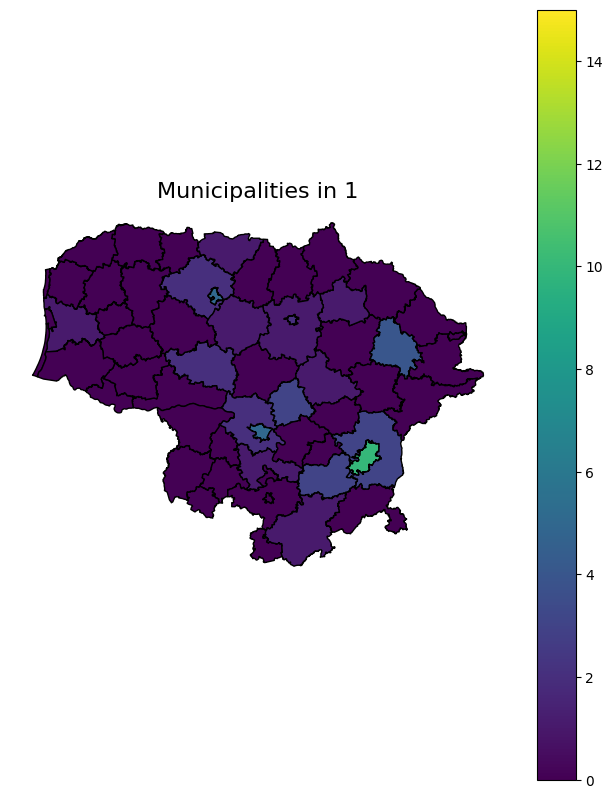

In [ ]:


data = pd.DataFrame({
    "SAV_PAV": munis,
})

for year in years:
    print(f"month {year}")
    for muni in munis:
        if muni not in df['name'].unique(): 
            data.loc[data['SAV_PAV'] == muni, year] = 0
        else: 
            data.loc[data['SAV_PAV'] == muni, year] = df.loc[(df['name'] == muni) & (df['year'] == 2015) & (df['month'] == year), 'infection'].squeeze()

gdf_new = gdf.merge(data, on="SAV_PAV")
vmin = 0
vmax = 15

fig, ax = plt.subplots(figsize=(8, 10))
gdf_new.plot(
    column=years[0],
    ax=ax,
    cmap="viridis",
    edgecolor="black",
    vmin=vmin,
    vmax=vmax,
    legend=True  
)
ax.set_axis_off()
def update(year):

    ax.clear()
    ax.set_title(f"Municipalities in {year}", fontsize=16)
    ax.set_axis_off()
    gdf_new.plot(
        ax=ax,
        column=year,           
        cmap="viridis",         
        legend=False,
        vmin=vmin,
        vmax=vmax,
        edgecolor="black"
    )

ani = FuncAnimation(fig, update, frames=years, repeat=True)

#ani.save("municipalities_animation.gif", writer="pillow", fps=1)
ani.save("municipalities_animation.mp4", writer="ffmpeg", fps=1)

plt.show()